# Joint training of both arms: VizDoom *Defend the Center*

Digital twin of the off-axis holography bench. Both arms of the hologram are trained together (main text, "Joint
training and drift robustness", Fig. 3e,f; Methods "Joint training"; Supplementary Note 4D):

* the **object arm**: a phase mask $\theta$ on the $32\times32$ object cells, added to the data phase $\varphi$, trained
  **in situ** through the ten-probe model of the diffuser;
* the **reference arm**: the pattern $E$ on the $100\times100$ reference cells, trained **offline** on the fields just
  measured.

Both error fields come from the same measured field, so $\theta$ and $E$ are updated from the same frames. The class is
read all-optically from the raw frame with the fringe-matched masks of Eq. (7): one frame, three fixed masks, an argmax.

| Section | In the manuscript |
|---|---|
| 1 · Bench, data and the ten-probe object model | Methods; Supplementary Notes 3A, 4B |
| 2 · One epoch of joint training | Fig. 3e; Methods "Joint training"; Supplementary Note 4D |
| 3 · Training, test and closed loop (with the bench's detector offsets) | Fig. 3d,f; Supplementary Fig. S5 |

The optics are in [`twin.py`](../Object/twin.py) and the reference arm, the two-arm bench and the offline training in
[`reference.py`](../Reference/reference.py). **On Colab:** upload `twin.py`, `reference.py` and (to skip generating the
game frames) `vizdoom_defend_the_center.npz` from `data/` to the working directory; the first cell installs VizDoom. The
training and one played episode are saved as GIFs in `gifs/`.

In [1]:
import os
import sys
import time
import importlib.metadata
import subprocess

try:
    vizdoom_version = importlib.metadata.version("vizdoom")
except importlib.metadata.PackageNotFoundError:
    vizdoom_version = None
if vizdoom_version != "1.3.1":                                    # the bench's VizDoom build (e.g. on Colab)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vizdoom==1.3.1"], check=True, capture_output=True)
sys.path += [os.path.join("..", "Object"), os.path.join("..", "Reference")]   # on Colab both files sit next to this one

import numpy as np
import scipy.optimize
import matplotlib.pyplot as plt
from IPython.display import Image, display
import vizdoom as vzd
import twin as tw
import reference as ref

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
DATA = os.path.join("..", "data") if os.path.isdir(os.path.join("..", "data")) else "."
os.makedirs("gifs", exist_ok=True)
T_START = time.time()

## 1 · Bench, data and the ten-probe object model

The bench is the twin of `reference.py`, set like the bench build of the article runs. The three detectors are the hard
24-pixel boxes of the bench's *Defend the Center* runs (LEFT, RIGHT, ATTACK).

**Data** (as in `../Reference/Computing.ipynb`): game frames of *Defend the Center* labelled by an oracle (turn toward the
largest monster in view, shoot when it is centred, turn left when nothing is in view), encoded by a fixed colour
projection and a column maximum (the horizontal position of the monsters reaches the SLM), and split by episode.

**Object model**: the thin-screen model $T_O \cong P_{z_s}\mathrm{diag}(D)P_{-z_s}F$ (Eq. 4), fitted from ten random probes
read with the flat reference (Eq. 5), on the readout window.

In [2]:
bench = ref.Bench(seed=0)
det = ref.Detectors([(13, 33), (43, 16), (43, 50)], size=24)               # LEFT, RIGHT, ATTACK
ACTIONS = ["LEFT", "RIGHT", "ATTACK"]
LDA, LO, HI = np.array([0.18311, -0.57792, 0.23897]), -9.1941, 14.2908
TARGETS = ("MarineChainsawVzd", "Demon")


def make_game():
    game = vzd.DoomGame()
    game.load_config(os.path.join(vzd.scenarios_path, "defend_the_center.cfg"))
    game.set_screen_resolution(vzd.ScreenResolution.RES_160X120)
    game.set_screen_format(vzd.ScreenFormat.RGB24)
    game.set_labels_buffer_enabled(True)
    game.set_render_hud(False); game.set_render_crosshair(False); game.set_render_weapon(False)
    game.set_window_visible(False)
    game.add_available_game_variable(vzd.GameVariable.KILLCOUNT)
    game.init()
    return game


def band(rgb):
    p = rgb[44:76].astype(float) @ LDA
    return np.clip(np.round(255 * (p - LO) / (HI - LO)), 0, 255).astype(np.uint8)


def oracle(state):
    best = None
    for label in state.labels:
        if label.object_name in TARGETS and label.width >= 1 and label.height >= 0.8 * label.width \
                and (best is None or label.height > best.height):
            best = label
    if best is None:
        return 0
    e = best.x + best.width / 2 - 80
    return 2 if abs(e) <= max(1, 0.5 * best.width) else (0 if e < 0 else 1)


def phase(bands):
    column = bands.reshape(bands.shape[:-1] + (32, 5)).max(-1).max(-2)                 # one value per column
    return np.pi * np.repeat(column[..., None, :], 32, axis=-2) / 255


def make_dataset(path, n_frames=16000, rng=np.random.default_rng(0)):
    # a noisy oracle plays; frames are stored with the oracle's action, near-duplicates dropped, classes capped,
    # episodes split 80/10/10
    game, bands, labels, episodes, ep = make_game(), [], [], [], 0
    while len(labels) < n_frames:
        game.set_seed(ep); game.new_episode(); held, left = 0, 0
        while not game.is_episode_finished():
            state = game.get_state()
            label = oracle(state)
            if left > 0:
                action, left = held, left - 1
            elif rng.random() < 0.1:
                held = int(rng.integers(3)); action, left = held, int(rng.integers(2, 8))
            elif rng.random() < 0.7:
                action = label
            else:
                action = int(rng.integers(3))
            bands.append(band(state.screen_buffer)); labels.append(label); episodes.append(ep)
            game.make_action(np.eye(3, dtype=int)[action].tolist(), 4)
        ep += 1
    game.close()
    bands, labels, episodes = np.array(bands), np.array(labels), np.array(episodes)
    cells = bands.reshape(len(bands), 32, 32, 5).mean(-1)
    keep, last = [], None
    for i in range(len(labels)):
        if last is None or episodes[i] != episodes[last] or np.mean((cells[i] - cells[last])**2) >= 4.0:
            keep.append(i); last = i
    keep = np.array(keep)
    n = 3 * np.bincount(labels[keep]).min()
    keep = np.sort(np.concatenate([rng.permutation(keep[labels[keep] == c])[:n] for c in range(3)]))
    order = rng.permutation(np.unique(episodes[keep]))
    part = {e: 0 if k < 0.8 * len(order) else (1 if k < 0.9 * len(order) else 2) for k, e in enumerate(order)}
    np.savez_compressed(path, band=bands[keep], labels=labels[keep], split=[part[e] for e in episodes[keep]],
                        episode=episodes[keep])


path = os.path.join(DATA, "vizdoom_defend_the_center.npz")
if not os.path.exists(path):
    make_dataset(path)
data = np.load(path)
PHI, Y, split = phase(data["band"]), data["labels"].astype(int), data["split"]
TRAIN, VAL, TEST = (np.nonzero(split == k)[0] for k in range(3))
VAL_SEL = np.random.default_rng(3).permutation(VAL)[:300]                  # 300 validation frames per epoch
W_CLS = len(TRAIN) / (3 * np.bincount(Y[TRAIN], minlength=3))
print(f"{len(Y)} frames; training / validation / test = {len(TRAIN)} / {len(VAL)} / {len(TEST)}; "
      f"LEFT / RIGHT / ATTACK = {np.bincount(Y).tolist()}")

rng = np.random.default_rng(5)
P_probe, P_check = 2 * np.pi * rng.random((10, tw.NC, tw.NC)), 2 * np.pi * rng.random((40, tw.NC, tw.NC))
model = tw.fit_screen(np.exp(1j * P_probe), bench.acquire(P_probe), mask=ref.WINDOW)
print(f"ten-probe object model: model accuracy on the window "
      f"{tw.model_accuracy(model, np.exp(1j * P_check), bench.acquire(P_check), ref.WINDOW):.3f}")

10000 frames; training / validation / test = 8059 / 833 / 1108; LEFT / RIGHT / ATTACK = [4483, 3771, 1746]


ten-probe object model: model accuracy on the window 0.866


## 2 · One epoch of joint training

The scores are the interference terms $s_c = \sum_{M_c}\mathrm{Re}(\hat O R^*)$, divided by a fixed spread $\sigma$, and the
loss is the class-weighted cross-entropy. Each epoch (Supplementary Note 4D):

1. **$\theta$ in situ.** Each training frame is written as $\varphi_n + \theta$ with the flat reference and read once. The
   **measured** field $\hat O_n$ is scored with the current reference (through the reference model, $R = T_R\{E\}$), so
   $\partial L/\partial O^* = \tfrac12\sum_c g_c M_c R$, rotated into the object model's gauge by one phase per frame
   (Supplementary Eq. S12), and the object-arm gradient $\partial L/\partial\theta = 2\,\mathrm{Im}[X_O^*\odot
   T_O^{\mathrm H}\{W\}]$ (Eq. 3) updates $\theta$ with Adam, in batches of 50.
2. **Refit and $E$ offline.** The validation frames are read with the flat reference and the current $\theta$. The object
   model is refitted on fields of the epoch and kept only if it predicts the validation fields better. $E$ is then
   trained offline on the fields just measured (`ref.train_reference`, 5 epochs, from the current $E$).
3. **All-optical validation.** The validation frames are read with $\theta$ and the trained $E$, from the raw frame with
   the fringe-matched masks; the epoch with the best balanced validation accuracy is kept.

Both arms start untrained ($\theta = 0$, $E$ flat). Each epoch uses 4,000 training frames; the learning rate of $\theta$
falls from 0.05 to 0.005 over the epochs (cosine).

In [3]:
EPOCHS, PER_EPOCH, BATCH = 8, 4000, 50
sigma = np.std(det.scores(bench.acquire(PHI[TRAIN[:300]], detectors=det), det.on_pixels(ref.MODEL.forward(ref.FLAT))))


def theta_step(theta, E, ids, opt):
    # one in situ minibatch: flat-reference reads of the frames written with theta; gradient through the object model
    X = np.exp(1j * (PHI[ids] + theta))
    O = bench.acquire(PHI[ids] + theta)                                       # measured fields, one read per frame
    R = ref.MODEL.forward(E)
    s = det.scores(det.on_pixels(O), det.on_pixels(R)) / sigma
    L, ds = ref.weighted_ce(s, Y[ids], W_CLS)
    W_pix = np.zeros((len(ids), 90 * 90), complex)
    W_pix[:, det.pixels] = 0.5 * (ds / sigma) @ det.to_box.T * det.on_pixels(R)    # dL/dO* = 1/2 sum_c g_c M_c R
    W = np.zeros((len(ids), tw.N, tw.N), complex)
    W[:, ref.W90, ref.W90] = W_pix.reshape(-1, 90, 90)
    pred = model.forward(X)
    for n in range(len(ids)):                                                 # into the model's gauge (Eq. S12)
        zeta = np.vdot(pred[n][ref.WINDOW], O[n][ref.WINDOW])
        W[n] *= np.conj(zeta) / abs(zeta)
    theta = opt.step(theta, np.sum(tw.object_gradient(X, W, model), axis=0))
    return theta, O, np.mean(s.argmax(1) == Y[ids])


def raw_read(ids, theta, E):
    # the all-optical read: one raw frame per input, fringe-matched masks, argmax
    raw, demod = bench.read(PHI[ids] + theta, E, det)
    return raw.argmax(1), demod.argmax(1)


theta, E = np.zeros((tw.NC, tw.NC)), ref.FLAT.copy()
opt = tw.Adam((tw.NC, tw.NC), 0.05, 0.05)
history, best = [], dict(bal=-1)
gif_theta, gif_curve, running = [], [], []
pred0 = raw_read(VAL_SEL, theta, E)[0]
history.append(ref.balanced_accuracy(pred0, Y[VAL_SEL]))
print(f"untrained (theta = 0, flat reference): validation balanced accuracy {history[0]:.3f}")
order_rng = np.random.default_rng(11)
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    opt.lr = opt.lr_final = 0.05 * (0.1 + 0.9 * 0.5 * (1 + np.cos(np.pi * (epoch - 1) / EPOCHS)))
    sel = order_rng.permutation(TRAIN)[:PER_EPOCH]
    O_epoch, X_fit, O_fit = [], [], []
    for b in range(0, PER_EPOCH, BATCH):                                      # 1. theta in situ
        ids = sel[b:b + BATCH]
        theta, O, acc = theta_step(theta, E, ids, opt)
        O_epoch.append(det.on_pixels(O).astype(np.complex64))
        if b >= PER_EPOCH - 200:                                              # the last 200 fields: for the refit
            X_fit.append(np.exp(1j * (PHI[ids] + theta))); O_fit.append(O)
        running.append(acc)
        if (b // BATCH) % 4 == 0:
            gif_theta.append(np.mod(theta, 2 * np.pi)); gif_curve.append(np.mean(running[-10:]))
    O_epoch = np.concatenate(O_epoch)
    O_val = bench.acquire(PHI[VAL_SEL] + theta)                                # 2. refit, then E offline
    X_val = np.exp(1j * (PHI[VAL_SEL] + theta))
    refit = tw.fit_screen(np.concatenate(X_fit), np.concatenate(O_fit), arm=model, mask=ref.WINDOW)
    if tw.model_accuracy(refit, X_val, O_val, ref.WINDOW) > tw.model_accuracy(model, X_val, O_val, ref.WINDOW):
        model = refit
    E, _ = ref.train_reference(O_epoch, Y[sel], det.on_pixels(O_val), Y[VAL_SEL], det, epochs=5, E0=E, sigma=sigma,
                               lr=opt.lr, seed=epoch)
    bal = ref.balanced_accuracy(raw_read(VAL_SEL, theta, E)[0], Y[VAL_SEL])     # 3. all-optical validation
    history.append(bal)
    if bal > best["bal"]:
        best = dict(bal=bal, theta=theta.copy(), E=E.copy(), epoch=epoch)
    print(f"epoch {epoch}: validation balanced accuracy {bal:.3f} (raw frame, bench)  [{time.time() - t0:.0f} s]")
theta, E = best["theta"], best["E"]
print(f"kept epoch {best['epoch']}")

untrained (theta = 0, flat reference): validation balanced accuracy 0.308


epoch 1: validation balanced accuracy 0.775 (raw frame, bench)  [159 s]


epoch 2: validation balanced accuracy 0.841 (raw frame, bench)  [158 s]


epoch 3: validation balanced accuracy 0.851 (raw frame, bench)  [162 s]


epoch 4: validation balanced accuracy 0.838 (raw frame, bench)  [158 s]


epoch 5: validation balanced accuracy 0.838 (raw frame, bench)  [165 s]


epoch 6: validation balanced accuracy 0.839 (raw frame, bench)  [160 s]


epoch 7: validation balanced accuracy 0.819 (raw frame, bench)  [162 s]


epoch 8: validation balanced accuracy 0.830 (raw frame, bench)  [160 s]
kept epoch 3


## 3 · Test, training curve and closed loop

The kept $\theta$ and $E$ are written once and every test frame is read once from the raw frame (the demodulated read of
the same frames is given for comparison). The bench then plays 30 episodes on unseen seeds (1,000,000–1,000,029), one
raw-frame read per game frame, against a digital linear classifier on the same inputs (the bench's recipe), random
actions and the oracle; the score is the number of kills per episode. The baselines play first; the bench's episodes follow below, with its
detector offsets.

test, raw-frame read: accuracy 0.793, balanced 0.823 (recall LEFT / RIGHT / ATTACK 0.75 / 0.78 / 0.93)
test, demodulated read: accuracy 0.791, balanced 0.820


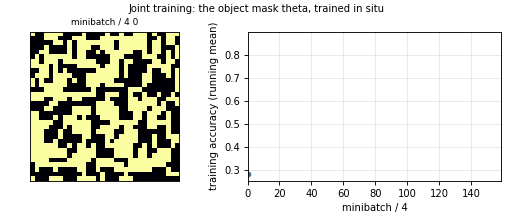

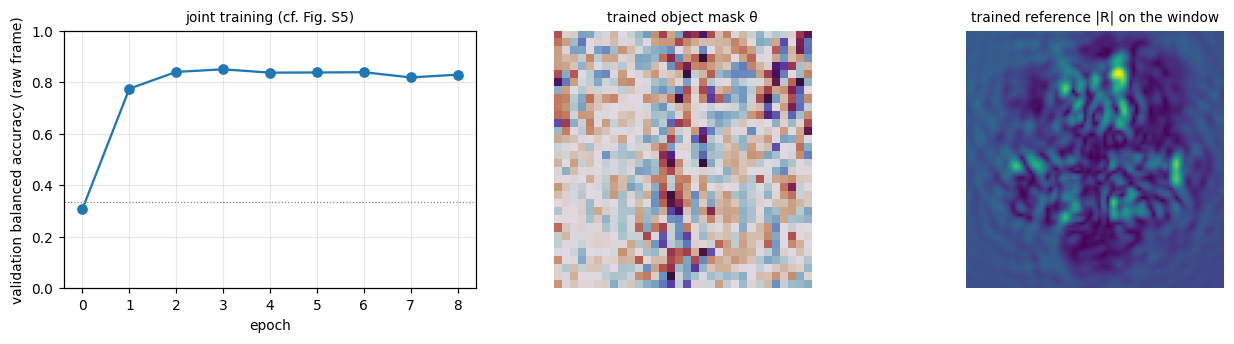

In [4]:
pred_raw, pred_demod = raw_read(TEST, theta, E)
recall = [np.mean(pred_raw[Y[TEST] == k] == k) for k in range(3)]
test_raw = dict(acc=np.mean(pred_raw == Y[TEST]), bal=np.mean(recall))
test_demod = dict(acc=np.mean(pred_demod == Y[TEST]), bal=ref.balanced_accuracy(pred_demod, Y[TEST]))
print(f"test, raw-frame read: accuracy {test_raw['acc']:.3f}, balanced {test_raw['bal']:.3f} "
      f"(recall LEFT / RIGHT / ATTACK {' / '.join(f'{v:.2f}' for v in recall)})")
print(f"test, demodulated read: accuracy {test_demod['acc']:.3f}, balanced {test_demod['bal']:.3f}")

path = tw.save_gif("gifs/joint_training.gif", gif_theta, gif_curve, "training accuracy (running mean)",
                   "Joint training: the object mask theta, trained in situ", xlabel="minibatch / 4", own_scale=False)
display(Image(filename=path))

fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
axs[0].plot(range(len(history)), history, "o-")
axs[0].axhline(1 / 3, color="gray", ls=":", lw=0.8)
axs[0].set_xlabel("epoch"); axs[0].set_ylabel("validation balanced accuracy (raw frame)"); axs[0].set_ylim(0, 1)
axs[0].grid(alpha=0.3); axs[0].set_title("joint training (cf. Fig. S5)")
axs[1].imshow(np.mod(theta, 2 * np.pi), cmap="twilight", vmin=0, vmax=2 * np.pi); axs[1].axis("off")
axs[1].set_title("trained object mask θ")
axs[2].imshow(np.abs(bench._ref.forward(ref.slm_response(E))[ref.W90, ref.W90]), cmap="viridis"); axs[2].axis("off")
axs[2].set_title("trained reference |R| on the window")
plt.tight_layout(); plt.show()

In [5]:
def logistic_regression(X, y, C):
    # class-balanced multinomial logistic regression: sum_n w_n CE_n + |W|^2 / (2C), intercept not penalised
    n, f = X.shape
    w = (len(y) / (3 * np.bincount(y, minlength=3)))[y]

    def loss(p):
        Wt, b = p[:3 * f].reshape(f, 3), p[3 * f:]
        z = X @ Wt + b
        z = z - z.max(1, keepdims=True)
        P = np.exp(z); P /= P.sum(1, keepdims=True)
        G = w[:, None] * (P - np.eye(3)[y])
        L = -np.sum(w * np.log(P[np.arange(n), y] + 1e-300)) + np.sum(Wt * Wt) / (2 * C)
        return L, np.concatenate([(X.T @ G + Wt / C).ravel(), G.sum(0)])
    p = scipy.optimize.minimize(loss, np.zeros(3 * f + 3), jac=True, method="L-BFGS-B", options=dict(maxiter=3000)).x
    Wt, b = p[:3 * f].reshape(f, 3), p[3 * f:]
    return lambda X_new: (X_new @ Wt + b).argmax(1)


features = lambda phi: phi.reshape(len(phi), -1) / np.pi
linear = max([logistic_regression(features(PHI[TRAIN]), Y[TRAIN], C) for C in (0.01, 0.1, 1.0, 10.0)],
             key=lambda m: np.mean(m(features(PHI[VAL])) == Y[VAL]))


def play(policy, seeds, record=False):
    # kills per episode; with record, also every step of the first episode (for the GIF)
    game, kills, frames = make_game(), [], []
    for s in seeds:
        game.set_seed(int(s)); game.new_episode()
        while not game.is_episode_finished():
            state = game.get_state()
            action = policy(state)
            if record and s == seeds[0]:
                frames.append((state.screen_buffer.copy(), *policy.last, action))
            game.make_action(np.eye(3, dtype=int)[action].tolist(), 4)
        kills.append(game.get_game_variable(vzd.GameVariable.KILLCOUNT))
    game.close()
    return np.array(kills), frames


encode = lambda rgb: phase(band(rgb)[None])
rng_play = np.random.default_rng(0)
seeds = np.arange(1_000_000, 1_000_030)
policies = {"digital linear": lambda st: int(linear(features(encode(st.screen_buffer)))[0]),
            "random": lambda st: int(rng_play.integers(3)),
            "oracle": oracle}
kills = {name: play(pol, seeds)[0] for name, pol in policies.items()}
sem = lambda k: np.std(k, ddof=1) / np.sqrt(len(k))
for name, k in kills.items():
    print(f"{name:28s} kills per episode {k.mean():5.2f} ± {sem(k):.2f}")

digital linear               kills per episode  3.53 ± 0.58
random                       kills per episode  1.47 ± 0.19
oracle                       kills per episode 15.40 ± 1.06


### Closed loop with the bench's detector offsets

On the bench, the three detectors carried slightly different offsets than the model predicts, strongest on dim frames,
where they tipped the decision toward RIGHT. With nothing in view the scores are close, so this lean kept the bench
turning one way to find the next monster, while frames with a monster in view were decided by the trained arms. The
twin's detectors have no such lean, so we add the bench's offsets, measured with the same detectors in the *Defend the
Center* session of 2026-10-25 (`../Reference/Computing.ipynb`), to reproduce the bench's closed-loop behaviour; $\theta$,
the reference and the read are unchanged. The digital baselines get no offset, since the offset is a property of the
optical read.

In [6]:
# offsets of the bench's raw read relative to its own model, in score spreads, per detector L/R/A (2026-10-25 session)
BENCH_OFFSET = {"dim": np.array([-0.33, 0.22, 0.11]), "other": np.array([-0.25, 0.09, 0.16])}
DIM = 60                                                   # brightest column below 60 of 255: nothing in view


def kind(phase):
    return "dim" if phase.max() * 255 / np.pi < DIM else "other"


# the twin's own offsets in the same units, so that the twin ends up with the bench's offsets
s_twin = bench.read(PHI[TEST] + theta, E, det)[0]
s_model = det.scores(bench.acquire(PHI[TEST] + theta, detectors=det), det.on_pixels(ref.MODEL.forward(E)))
scale = np.sum((s_twin - s_twin.mean()) * (s_model - s_model.mean())) / np.sum((s_model - s_model.mean()) ** 2)
residual = (s_twin / scale - s_model) / s_model.std()
kinds = np.array([kind(p) for p in PHI[TEST]])
shift = {}
for k in ("dim", "other"):
    own = residual[kinds == k].mean(0)
    own = own - own.mean()
    shift[k] = (BENCH_OFFSET[k] - own) * scale * s_model.std()
    print(f"{k:5s} frames ({np.mean(kinds == k):.0%} of test): twin offset {np.round(own, 2)}, bench {BENCH_OFFSET[k]}")

pred = np.array([np.argmax(s + shift[k]) for s, k in zip(s_twin, kinds)])
dim_share = np.bincount(pred[kinds == "dim"], minlength=3) / np.sum(kinds == "dim")
print(f"test, twin + bench offsets: accuracy {np.mean(pred == Y[TEST]):.3f}, balanced "
      f"{ref.balanced_accuracy(pred, Y[TEST]):.3f}, dim frames L/R/A {np.round(dim_share, 2)}")


def offset_policy(state):
    x = encode(state.screen_buffer)
    s = bench.read(x + theta, E, det)[0][0] + shift[kind(x)]
    offset_policy.last = (np.mod(x[0] + theta, 2 * np.pi), bench.last_frame, s)     # for the GIF
    return int(np.argmax(s))


kills["optical, joint (raw frame)"], episode = play(offset_policy, seeds, record=True)
k, lin = kills["optical, joint (raw frame)"], kills["digital linear"]
print(f"\nkills per episode (the same 30 seeds): optical {k.mean():.2f} ± {sem(k):.2f}, linear {lin.mean():.2f}; "
      f"bench 8.83 ± 0.93")
print(f"paired: optical - linear {np.mean(k - lin):+.2f} ± {sem(k - lin):.2f}")

ref.save_episode_gif("gifs/joint_episode.gif", episode, det, "raw",
                     "Defend the Center, one episode played by the jointly trained bench (all-optical read)", fps=6)

dim   frames (4% of test): twin offset [-0.2  -0.11  0.31], bench [-0.33  0.22  0.11]
other frames (96% of test): twin offset [-0.12 -0.08  0.2 ], bench [-0.25  0.09  0.16]
test, twin + bench offsets: accuracy 0.779, balanced 0.813, dim frames L/R/A [0.06 0.94 0.  ]



kills per episode (the same 30 seeds): optical 11.23 ± 0.78, linear 3.53; bench 8.83 ± 0.93
paired: optical - linear +7.70 ± 0.98


One episode played by the jointly trained bench (linked GIF, `gifs/joint_episode.gif`): the game, the phase written
on the object arm ($\varphi + \theta$) and the raw camera frame with the chosen detector.

![Joint episode](gifs/joint_episode.gif)

## Summary: the twin next to the bench

The bench values are those of the article (main text; Supplementary Note 4D, Fig. S5; Fig. 3d).

In [7]:
rows = [("validation balanced accuracy, start → kept epoch", f"{history[0]:.2f} → {best['bal']:.2f}", "0.21 → 0.81"),
        ("test, raw-frame read: accuracy / balanced", f"{test_raw['acc']:.3f} / {test_raw['bal']:.3f}", "0.746 / 0.763"),
        ("test, demodulated read: accuracy / balanced", f"{test_demod['acc']:.3f} / {test_demod['bal']:.3f}", "0.758 / 0.778")]
for name, b in [("optical, joint (bench offsets)", "8.83 ± 0.93"), ("digital linear", "3.50 ± 0.70"),
                ("random", "1.37 ± 0.20"), ("oracle", "12.03 ± 0.74")]:
    key = "optical, joint (raw frame)" if name.startswith("optical") else name
    rows.append((f"kills per episode, {name}", f"{kills[key].mean():.2f} ± {sem(kills[key]):.2f}", b))
print(f"{'':52s} {'twin':>14s} {'bench':>14s}")
for name, t, b in rows:
    print(f"{name:52s} {t:>14s} {b:>14s}")
print(f"\nbench reads in the twin: {bench.reads:,}; runtime {time.time() - T_START:.0f} s")

                                                               twin          bench
validation balanced accuracy, start → kept epoch        0.31 → 0.85    0.21 → 0.81
test, raw-frame read: accuracy / balanced             0.793 / 0.823  0.746 / 0.763
test, demodulated read: accuracy / balanced           0.791 / 0.820  0.758 / 0.778
kills per episode, optical, joint (bench offsets)      11.23 ± 0.78    8.83 ± 0.93
kills per episode, digital linear                       3.53 ± 0.58    3.50 ± 0.70
kills per episode, random                               1.47 ± 0.19    1.37 ± 0.20
kills per episode, oracle                              15.40 ± 1.06   12.03 ± 0.74

bench reads in the twin: 46,951; runtime 1610 s


**Take-aways.** Both arms are trained from the same measured fields: the object mask in situ through a ten-probe model
of the diffuser, the reference offline through a model of its own free-space path, and the result is read all-optically
from one raw frame. The twin classifies the test frames with a balanced accuracy of 0.823 from the raw frame (bench
0.763) and, with the bench's measured detector offsets, kills 11.2 ± 0.8 enemies per episode (bench 8.8 ± 0.9), against
3.5 for the linear classifier and 1.5 for random actions. On the same seeds the twin's oracle (VizDoom 1.3.1 on this
computer) plays better than the bench's, so kills are best compared with the linear classifier and random actions of the
same table.